In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project folder and dataset path
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_dir / "data" / "marketing_AB.csv"

# Load the CSV
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Actual column names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (588101, 7)
Actual column names:
['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [2]:
# Check data types and non-null counts
df.info()

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check summary statistics
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Unnamed: 0     588101 non-null  int64
 1   user id        588101 non-null  int64
 2   test group     588101 non-null  str  
 3   converted      588101 non-null  bool 
 4   total ads      588101 non-null  int64
 5   most ads day   588101 non-null  str  
 6   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(4), str(2)
memory usage: 32.6 MB
Missing values:
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,588101.0,NaN,NaN,NaN,294050.0,169770.279668,0.0,147025.0,294050.0,441075.0,588100.0
user id,588101.0,NaN,NaN,NaN,1310692.215793,202225.983128,900000.0,1143190.0,1313725.0,1484088.0,1654483.0
test group,588101,2,ad,564577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
converted,588101,2,False,573258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total ads,588101.0,NaN,NaN,NaN,24.820876,43.715181,1.0,4.0,13.0,27.0,2065.0
most ads day,588101,7,Friday,92608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
most ads hour,588101.0,NaN,NaN,NaN,14.469061,4.834634,0.0,11.0,14.0,18.0,23.0


In [3]:
# Remove an exported index column if present
unnamed_cols = [col for col in df.columns if str(col).startswith("Unnamed:")]

df = df.drop(columns=unnamed_cols)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Standardize column names for easier Python coding
df.columns = (df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True))

print("Cleaned shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isnull().sum())

df.head()

Cleaned shape: (588101, 6)
Columns: ['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']
Missing values:
 user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


Group proportions:
test_group
ad     0.96
psa    0.04
Name: proportion, dtype: float64
Group counts:
test_group
ad     564577
psa     23524
Name: count, dtype: int64


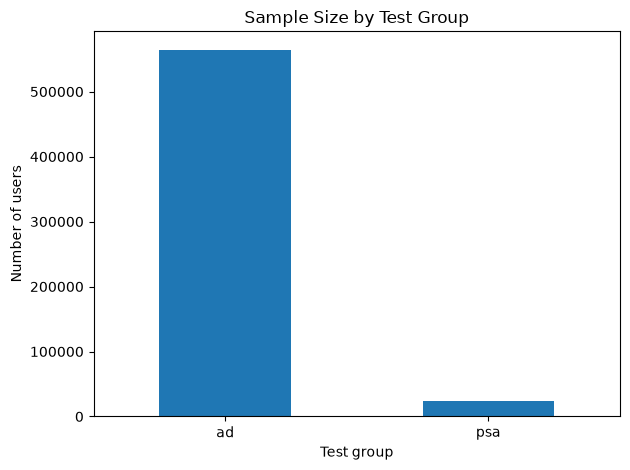

In [4]:
# Check proportions of users in each group
group_proportions = df["test_group"].value_counts(normalize=True)
print("Group proportions:")
print(group_proportions)

# Check actual sample sizes
print("Group counts:")
print(df["test_group"].value_counts())

# Visualize the imbalance
import matplotlib.pyplot as plt

df["test_group"].value_counts().plot(kind="bar")
plt.title("Sample Size by Test Group")
plt.xlabel("Test group")
plt.ylabel("Number of users")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Group Size Imbalance

The experiment has a highly imbalanced allocation, with approximately 96% of users in the ad group and 4% in the PSA group. The PSA group is much smaller, so its conversion rate will generally have greater sampling uncertainty. This can reduce the statistical power to detect a genuine difference and make the comparison less precise. The imbalance does not automatically invalidate the experiment, but the group sizes, confidence intervals, and statistical test assumptions must be considered when interpreting the results.

In [5]:
summary = df.groupby("test_group")["converted"].agg(
    users="count",
    conversions="sum",
    conversion_rate="mean")

summary["conversion_rate_percent"] = summary["conversion_rate"] * 100

print(summary)

             users  conversions  conversion_rate  conversion_rate_percent
test_group                                                               
ad          564577        14423         0.025547                 2.554656
psa          23524          420         0.017854                 1.785411


### Business Question and Hypotheses

**Business question:** Does the advertising campaign increase the conversion rate compared with the public service announcement (PSA)?

**Primary metric:** Conversion rate, defined as the proportion of users who converted in each group.

**Significance level:** $\alpha = 0.05$

**Null hypothesis ($H_0$):** The conversion rates are equal in the ad and PSA groups.

$
H_0: p_{\text{ad}} = p_{\text{PSA}}
$

**Alternative hypothesis ($H_1$):** The conversion rates differ between the ad and PSA groups.

$
H_1: p_{\text{ad}} \ne p_{\text{PSA}}
$

The test will use a 5% significance level. If the p-value is below 0.05, the null hypothesis will be rejected in favour of evidence that the conversion rates differ. The direction and practical importance of any difference will also be examined.

In [6]:
from statsmodels.stats.proportion import proportions_ztest

# Separate the two groups
ad = df[df["test_group"] == "ad"]
psa = df[df["test_group"] == "psa"]

# Number of conversions in each group
conversions = [int(ad["converted"].sum()), int(psa["converted"].sum())]

# Total users in each group
sample_sizes = [len(ad), len(psa)]

# Perform a two-tailed z-test
z_stat, p_value = proportions_ztest(count=conversions, nobs=sample_sizes, alternative="two-sided")

# Display results
print(f"Ad conversion rate: {ad['converted'].mean():.4%}")
print(f"PSA conversion rate: {psa['converted'].mean():.4%}")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.8g}")

# Decision at 5% significance level
alpha = 0.05

if p_value < alpha:
    print("Reject H0: Conversion rates differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Ad conversion rate: 2.5547%
PSA conversion rate: 1.7854%
Z-statistic: 7.3701
P-value: 1.7052807e-13
Reject H0: Conversion rates differ significantly.


In [7]:
from statsmodels.stats.proportion import proportion_confint

for name, group in [("Ad", ad), ("PSA", psa)]:
    conversions_count = int(group["converted"].sum())
    n = len(group)

    lower, upper = proportion_confint(conversions_count, n, alpha=0.05, method="wilson")

    print(f"{name} conversion rate: {group['converted'].mean():.4%}")
    print(f"95% CI: [{lower:.4%}, {upper:.4%}]\n")

Ad conversion rate: 2.5547%
95% CI: [2.5138%, 2.5961%]

PSA conversion rate: 1.7854%
95% CI: [1.6239%, 1.9627%]



In [8]:
ad_rate = ad["converted"].mean()
psa_rate = psa["converted"].mean()

absolute_difference = ad_rate - psa_rate
relative_lift = (absolute_difference / psa_rate) * 100

print(f"Absolute difference: {absolute_difference:.4%}")
print(f"Relative lift: {relative_lift:.2f}%")

Absolute difference: 0.7692%
Relative lift: 43.09%


### Statistical Test Results and Interpretation

A two-tailed two-proportion Z-test was conducted to compare the conversion rates of the ad and PSA groups, using a significance level of 0.05.

- **Ad conversion rate:** **2.5547 %**
- **PSA conversion rate:** **1.7854 %**
- **Absolute difference:** **0.7692**
- **Relative lift:** **43.09 %**
- **Z-statistic:** **7.3701**
- **P-value:** **1.7053  * 10^(-13)**

**Decision:** Reject the null hypothesis because the p-value is below 0.05.

**Interpretation:** The ad group had a higher observed conversion rate than the PSA group. The difference is statistically significant under the assumptions of the two-proportion Z-test. However, business importance, confidence intervals, and the unequal group sizes should be considered before making a recommendation.
The individual conversion-rate confidence intervals are:
- **Ad:** **2.5138 % – 2.5961 %**
- **PSA:** **1.6239 % – 1.9627 %**

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

# Headline metrics by experiment group
headline = (df.groupby("test_group")["converted"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "users", "sum": "conversions", "mean": "conversion_rate"}))

headline["conversion_rate_pct"] = headline["conversion_rate"] * 100

display(headline.round(4))

,users,conversions,conversion_rate,conversion_rate_pct
test_group,,,,
ad,564577,14423,0.0255,2.5547
psa,23524,420,0.0179,1.7854


In [10]:
# Conversion rate by day and test group
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_summary = (df.groupby(["most_ads_day", "test_group"], observed=True)["converted"]
    .agg(["count", "sum", "mean"])
    .reset_index()
    .rename(columns={"count": "users", "sum": "conversions", "mean": "conversion_rate"}))

day_summary["conversion_pct"] = day_summary["conversion_rate"] * 100

print(day_summary.sort_values("conversion_pct", ascending=False).head(10))

   most_ads_day test_group  users  conversions  conversion_rate  \
2        Monday         ad  83571         2778         0.033241   
10      Tuesday         ad  74572         2270         0.030440   
12    Wednesday         ad  77418         1963         0.025356   
6        Sunday         ad  82332         2027         0.024620   
3        Monday        psa   3502           79         0.022559   
0        Friday         ad  88805         1995         0.022465   
8      Thursday         ad  79077         1711         0.021637   
4      Saturday         ad  78802         1679         0.021307   
7        Sunday        psa   3059           63         0.020595   
9      Thursday        psa   3905           79         0.020230   

    conversion_pct  
2         3.324120  
10        3.044038  
12        2.535586  
6         2.461983  
3         2.255854  
0         2.246495  
8         2.163714  
4         2.130657  
7         2.059497  
9         2.023047  


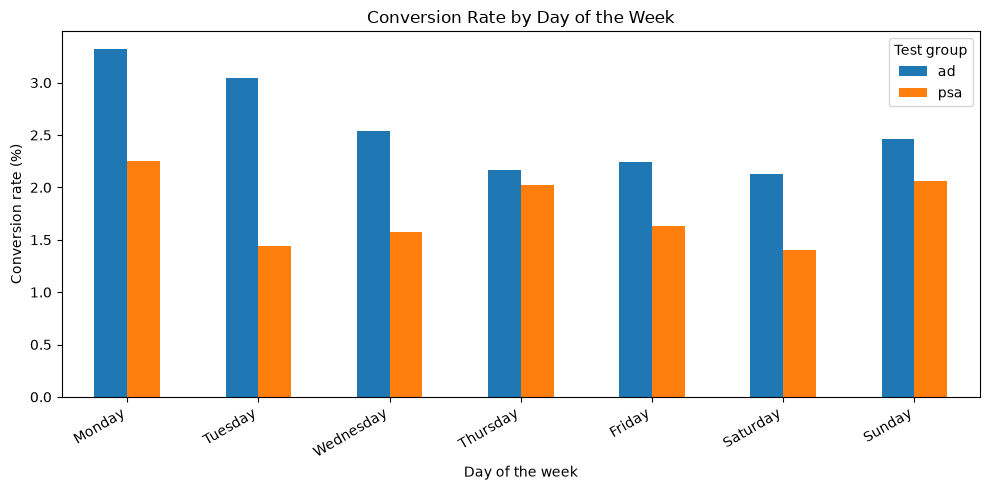

In [11]:
day_plot = day_summary.pivot(index="most_ads_day", columns="test_group", values="conversion_pct")

day_plot = day_plot.reindex([d for d in day_order if d in day_plot.index])

day_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Conversion Rate by Day of the Week")
plt.xlabel("Day of the week")
plt.ylabel("Conversion rate (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Test group")
plt.tight_layout()
plt.show()

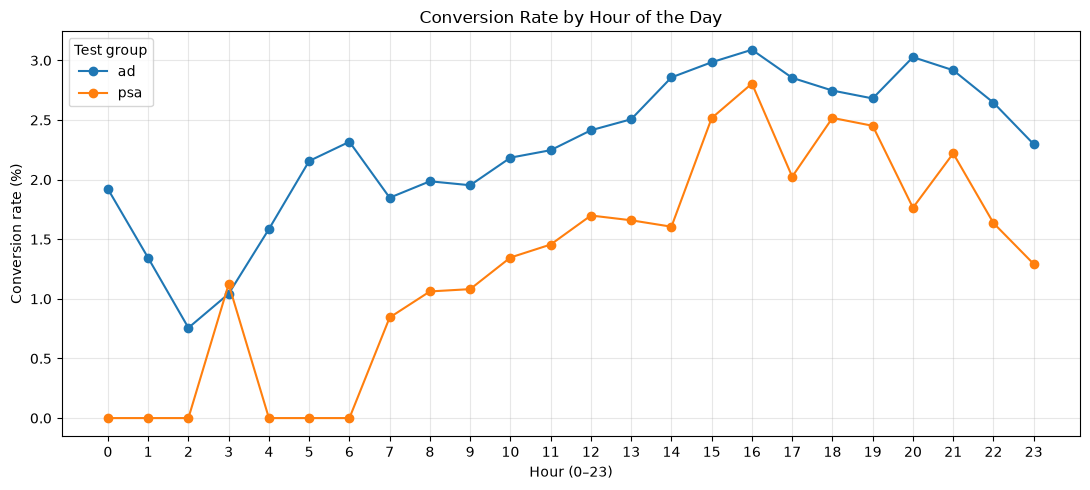

In [12]:
hour_summary = (df.groupby(["most_ads_hour", "test_group"], observed=True)["converted"]
    .mean()
    .mul(100)
    .reset_index(name="conversion_pct"))

hour_plot = hour_summary.pivot(index="most_ads_hour", columns="test_group", values="conversion_pct")

hour_plot.plot(kind="line", marker="o", figsize=(11, 5))

plt.title("Conversion Rate by Hour of the Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Conversion rate (%)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend(title="Test group")
plt.tight_layout()
plt.show()

In [13]:
# Create exposure buckets
bins = [0, 1, 5, 10, 20, 50, 100, np.inf]
labels = ["1", "2–5", "6–10", "11–20", "21–50", "51–100", "101+"]

df["ad_exposure_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels, include_lowest=True)

exposure_summary = (df.groupby(["ad_exposure_bucket", "test_group"], observed=True)["converted"]
    .agg(["count", "sum", "mean"])
    .reset_index()
    .rename(columns={"count": "users", "sum": "conversions", "mean": "conversion_rate"}))

exposure_summary["conversion_pct"] = (exposure_summary["conversion_rate"] * 100)

display(exposure_summary)

,ad_exposure_bucket,test_group,users,conversions,conversion_rate,conversion_pct
0,1,ad,54298,86,0.001584,0.158385
1,1,psa,2308,3,0.001300,0.129983
2,2–5,ad,115664,341,0.002948,0.294819
3,2–5,psa,5553,19,0.003422,0.342157
4,6–10,ad,79537,386,0.004853,0.485309
5,6–10,psa,3415,23,0.006735,0.673499
6,11–20,ad,123334,1036,0.008400,0.839995
7,11–20,psa,4150,34,0.008193,0.819277
8,21–50,ad,125541,3660,0.029154,2.915382
9,21–50,psa,5235,114,0.021777,2.177650


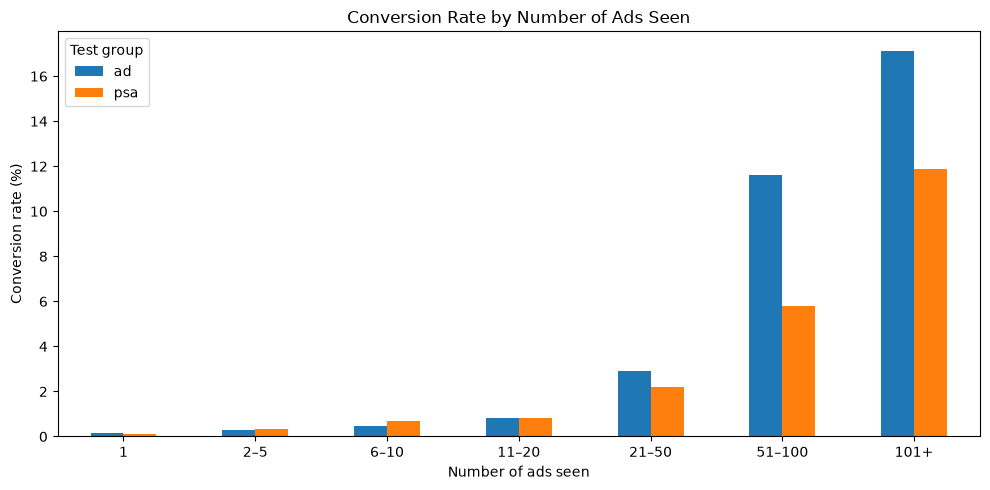

In [14]:
exposure_plot = exposure_summary.pivot(index="ad_exposure_bucket", columns="test_group", values="conversion_pct")

exposure_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Conversion Rate by Number of Ads Seen")
plt.xlabel("Number of ads seen")
plt.ylabel("Conversion rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Test group")
plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path
import sqlite3
import pandas as pd

# Find the project root
project_dir = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

# Create database in the data folder
db_path = project_dir / "data" / "ab.db"

con = sqlite3.connect(db_path)

# Store the dataset in a SQLite table
df.to_sql("ads", con, if_exists="replace", index=False)

# Run a SQL query
query = """
SELECT
    test_group,
    COUNT(*) AS n,
    SUM(CAST(converted AS INTEGER)) AS conversions,
    AVG(CAST(converted AS REAL)) AS conversion_rate
FROM ads
GROUP BY test_group;
"""

sql_summary = pd.read_sql_query(query, con)
display(sql_summary)

print("Database saved at:", db_path)

,test_group,n,conversions,conversion_rate
0,ad,564577,14423,0.025547
1,psa,23524,420,0.017854


Database saved at: C:\Users\store\Documents\Projects\ab-test-analysis\data\ab.db


In [16]:
from statsmodels.stats.proportion import (proportions_ztest, confint_proportions_2indep)
import numpy as np

# Calculate sample sizes and conversions
ad = df[df["test_group"] == "ad"]
psa = df[df["test_group"] == "psa"]

n_ad = len(ad)
n_psa = len(psa)

conv_ad = int(ad["converted"].sum())
conv_psa = int(psa["converted"].sum())

rate_ad = conv_ad / n_ad
rate_psa = conv_psa / n_psa

# Two-proportion, two-sided Z-test
z, p = proportions_ztest([conv_ad, conv_psa], [n_ad, n_psa], alternative="two-sided")

# 95% confidence interval for the difference (ad - PSA)
low, high = confint_proportions_2indep(conv_ad, n_ad, conv_psa, n_psa, method="newcomb")

print(f"Ad: {conv_ad:,}/{n_ad:,} = {rate_ad:.4%}")
print(f"PSA: {conv_psa:,}/{n_psa:,} = {rate_psa:.4%}")
print(f"Z-statistic: {z:.4f}")
print(f"P-value: {p:.8g}")
print(f"95% CI for absolute difference: [{low:.4%}, {high:.4%}]")

Ad: 14,423/564,577 = 2.5547%
PSA: 420/23,524 = 1.7854%
Z-statistic: 7.3701
P-value: 1.7052807e-13
95% CI for absolute difference: [0.5873%, 0.9360%]


In [17]:
absolute_lift = rate_ad - rate_psa
relative_lift = (absolute_lift / rate_psa) * 100

print(f"Absolute lift: {absolute_lift:.4%}")
print(f"Relative lift: {relative_lift:.2f}%")

Absolute lift: 0.7692%
Relative lift: 43.09%


In [18]:
from scipy.stats import chi2_contingency

contingency_table = np.array([[conv_ad, n_ad - conv_ad], [conv_psa, n_psa - conv_psa]])

chi2, p_chi2, dof, expected = chi2_contingency(contingency_table, correction=False)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Chi-square p-value: {p_chi2:.8g}")
print(f"Z-test p-value: {p:.8g}")
print(f"Absolute p-value difference: {abs(p - p_chi2):.10g}")

Chi-square statistic: 54.3181
Chi-square p-value: 1.7052807e-13
Z-test p-value: 1.7052807e-13
Absolute p-value difference: 4.064211384e-27


In [19]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

effect_size = proportion_effectsize(rate_ad, rate_psa)

power = NormalIndPower().solve_power(effect_size=effect_size, nobs1=n_psa, alpha=0.05, ratio=n_ad / n_psa, alternative="two-sided")

print(f"Observed Cohen's h: {effect_size:.4f}")
print(f"Estimated power: {power:.4%}")

Observed Cohen's h: 0.0530
Estimated power: 100.0000%


### Statistical Test — Conclusion

The ad group recorded a conversion rate of **2.5547%**, compared with **1.7854%** for the PSA group. The absolute difference was **0.7692 percentage points**, and the relative lift was **43.09%**.

A two-proportion Z-test was conducted at the 5% significance level. The p-value was **1.7053 × 10⁻¹³**, and the 95% confidence interval for the absolute difference was **[0.5873, 0.9360] percentage points**.

**Statistical decision:** Reject the null hypothesis.

**Business interpretation:** The results provide statistically significant evidence of a difference in conversion rates, with the ad group performing better in this dataset. Statistical significance alone does not establish profitability or practical importance. Campaign costs, profit per conversion, group-size imbalance, and experimental design should also be considered before making a rollout decision.

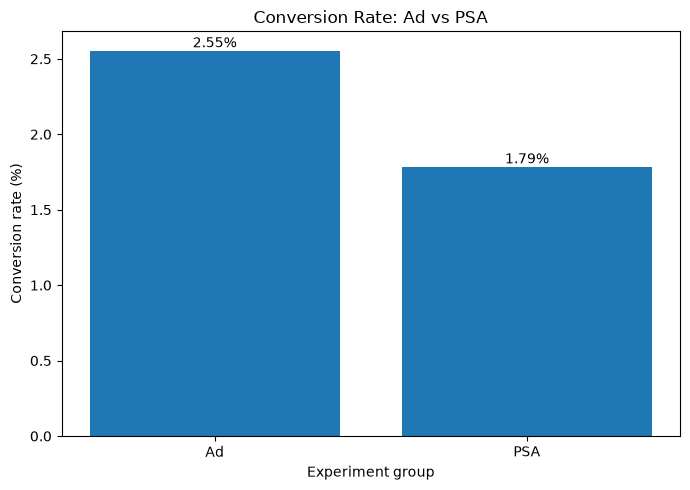

In [20]:
rates = [rate_ad * 100, rate_psa * 100]

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(["Ad", "PSA"], rates)
ax.set_title("Conversion Rate: Ad vs PSA")
ax.set_xlabel("Experiment group")
ax.set_ylabel("Conversion rate (%)")

for i, value in enumerate(rates):
    ax.text(i, value, f"{value:.2f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Business Insights and Recommendation

### Key Findings

- The ad group achieved a conversion rate of **2.5547%**, compared with **1.7854%** in the PSA group.
- The absolute lift was **0.7692 percentage points**, corresponding to a relative lift of **43.09%**.
- The two-proportion Z-test produced a p-value of **1.7053 × 10⁻¹³**, providing statistically significant evidence of a difference at the 5% significance level.

### Recommendation

The advertising campaign appears promising because the ad group achieved a higher conversion rate than the PSA group. However, before a full-scale rollout, the business should evaluate campaign costs, profit per conversion, and the validity of the experimental design. The unequal group sizes and potential differences in ad exposure should also be considered.

### Limitations

This analysis measures conversions rather than profitability. Differences between low- and high-exposure users represent associations, not proof that increasing ad exposure causes higher conversion. Segment-level tests also involve multiple comparisons, so the Bonferroni correction should be considered when interpreting their results. Further testing may be needed to confirm that the observed lift is reproducible.

In [21]:
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

# Create a copy 
df_day4 = df.copy()

# Convert day names into weekday/weekend categories
weekend_days = ["Saturday", "Sunday"]

df_day4["day_type"] = np.where(df_day4["most_ads_day"].str.strip().str.title().isin(weekend_days), "Weekend", "Weekday")

# Split users by median ad exposure
exposure_median = df_day4["total_ads"].median()

df_day4["exposure_level"] = np.where(df_day4["total_ads"] <= exposure_median, "Low exposure", "High exposure")

print("Median ad exposure:", exposure_median)
print(df_day4[["day_type", "exposure_level"]].value_counts())

Median ad exposure: 13.0
day_type  exposure_level
Weekday   Low exposure      218617
          High exposure     202433
Weekend   High exposure      86172
          Low exposure       80879
Name: count, dtype: int64


In [22]:
def calculate_segment_lift(data, segment_column):
    results = []

    for segment, subset in data.groupby(segment_column, dropna=False):
        ad = subset[subset["test_group"].str.lower() == "ad"]
        psa = subset[subset["test_group"].str.lower() == "psa"]

        n_ad, n_psa = len(ad), len(psa)

        if n_ad == 0 or n_psa == 0:
            continue

        conv_ad = int(ad["converted"].sum())
        conv_psa = int(psa["converted"].sum())

        # Skip segments with zero conversions in either group
        if conv_ad == 0 or conv_psa == 0:
            continue

        rate_ad = conv_ad / n_ad
        rate_psa = conv_psa / n_psa

        absolute_lift = rate_ad - rate_psa
        relative_lift = (absolute_lift / rate_psa * 100 if rate_psa > 0 else np.nan)

        # Avoid running a test if either group has no conversion events
        z_stat, p_value = proportions_ztest([conv_ad, conv_psa], [n_ad, n_psa])

        results.append({
            "segment_type": segment_column,
            "segment": str(segment),
            "ad_users": n_ad,
            "ad_conversions": conv_ad,
            "ad_rate_pct": rate_ad * 100,
            "psa_users": n_psa,
            "psa_conversions": conv_psa,
            "psa_rate_pct": rate_psa * 100,
            "absolute_lift_pp": absolute_lift * 100,
            "relative_lift_pct": relative_lift,
            "p_value": p_value})

    return pd.DataFrame(results)

# Test weekday/weekend, each hour, and exposure level
segment_results = pd.concat([calculate_segment_lift(df_day4, "day_type"), calculate_segment_lift(df_day4, "most_ads_hour"),
    calculate_segment_lift(df_day4, "exposure_level")], ignore_index=True)

# Bonferroni correction across all segment-level tests
alpha = 0.05
number_of_tests = len(segment_results)
corrected_alpha = alpha / number_of_tests

segment_results["bonferroni_alpha"] = corrected_alpha
segment_results["significant_after_correction"] = (segment_results["p_value"] < corrected_alpha)

# Display the results
display(segment_results.sort_values(["segment_type", "p_value"]).round(4))

print("Number of segment tests:", number_of_tests)
print("Original significance level:", alpha)
print("Bonferroni-adjusted significance level:", corrected_alpha)

,segment_type,segment,ad_users,ad_conversions,ad_rate_pct,psa_users,psa_conversions,psa_rate_pct,absolute_lift_pp,relative_lift_pct,p_value,bonferroni_alpha,significant_after_correction
0,day_type,Weekday,403443,10717,2.6564,17607,317,1.8004,0.8560,47.5425,0.0000,0.0023,True
1,day_type,Weekend,161134,3706,2.2999,5917,103,1.7407,0.5592,32.1243,0.0047,0.0023,False
20,exposure_level,High exposure,277682,13344,4.8055,10923,369,3.3782,1.4273,42.2505,0.0000,0.0023,True
21,exposure_level,Low exposure,286895,1079,0.3761,12601,51,0.4047,-0.0286,-7.0748,0.6079,0.0023,False
10,most_ads_hour,14,43779,1251,2.8575,1869,30,1.6051,1.2524,78.0244,0.0013,0.0023,True
9,most_ads_hour,13,45485,1140,2.5063,2170,36,1.6590,0.8473,51.0754,0.0129,0.0023,False
16,most_ads_hour,20,27846,843,3.0274,1077,19,1.7642,1.2632,71.6038,0.0168,0.0023,False
7,most_ads_hour,11,44149,992,2.2469,2061,30,1.4556,0.7913,54.3645,0.0170,0.0023,False
6,most_ads_hour,10,37454,818,2.1840,1485,20,1.3468,0.8372,62.1629,0.0292,0.0023,False
5,most_ads_hour,9,29802,582,1.9529,1202,13,1.0815,0.8714,80.5671,0.0309,0.0023,False


Number of segment tests: 22
Original significance level: 0.05
Bonferroni-adjusted significance level: 0.002272727272727273


In [23]:
display(segment_results[segment_results["p_value"] < segment_results["bonferroni_alpha"]]
    [[
        "segment_type",
        "segment",
        "ad_rate_pct",
        "psa_rate_pct",
        "absolute_lift_pp",
        "p_value",
        "bonferroni_alpha"
    ]])

,segment_type,segment,ad_rate_pct,psa_rate_pct,absolute_lift_pp,p_value,bonferroni_alpha
0,day_type,Weekday,2.656385,1.800420,0.855965,3.410313e-12,0.002273
10,most_ads_hour,14,2.857534,1.605136,1.252398,1.324581e-03,0.002273
20,exposure_level,High exposure,4.805497,3.378193,1.427304,6.067291e-12,0.002273


### Caution: Multiple Comparisons and Observational Segments

This analysis tests multiple segments, including weekday/weekend, individual hours, and ad-exposure levels. Conducting many hypothesis tests increases the probability of false-positive findings. To reduce this risk, the Bonferroni correction is applied using an adjusted significance threshold of \(\alpha_{\text{adjusted}} = 0.05/m\), where \(m\) is the number of segment-level tests.

The results of individual segments should be treated as exploratory, especially when some segments contain relatively few users or conversions. Ad-exposure levels were not independently randomized; therefore, differences between low- and high-exposure users indicate associations, not proof that additional ad exposure caused higher conversion. Other user characteristics may explain these differences.

In [24]:
# Overall campaign metrics
ad = df_day4[df_day4["test_group"].str.lower() == "ad"]
psa = df_day4[df_day4["test_group"].str.lower() == "psa"]

ad_rate = ad["converted"].mean()
psa_rate = psa["converted"].mean()
absolute_lift = ad_rate - psa_rate

# Assumptions: replace these with realistic business estimates
users_targeted = len(ad)          # Scenario: target the same number of users
value_per_conversion = 500        # Assumed revenue per conversion, in ₹
campaign_cost = 100000             # Assumed total campaign cost, in ₹

# Estimated business impact
incremental_conversions = users_targeted * absolute_lift
incremental_revenue = incremental_conversions * value_per_conversion

if campaign_cost > 0:
    roi = (incremental_revenue - campaign_cost) / campaign_cost * 100
else:
    roi = np.nan

print(f"Ad conversion rate: {ad_rate:.2%}")
print(f"PSA conversion rate: {psa_rate:.2%}")
print(f"Absolute lift: {absolute_lift:.4%}")
print(f"Users targeted: {users_targeted:,}")
print(f"Estimated incremental conversions: {incremental_conversions:,.0f}")
print(f"Assumed value per conversion: ₹{value_per_conversion:,.2f}")
print(f"Estimated incremental revenue: ₹{incremental_revenue:,.2f}")
print(f"Assumed campaign cost: ₹{campaign_cost:,.2f}")
print(f"Estimated ROI: {roi:.2f}%")

Ad conversion rate: 2.55%
PSA conversion rate: 1.79%
Absolute lift: 0.7692%
Users targeted: 564,577
Estimated incremental conversions: 4,343
Assumed value per conversion: ₹500.00
Estimated incremental revenue: ₹2,171,491.07
Assumed campaign cost: ₹100,000.00
Estimated ROI: 2071.49%


### Final Recommendation

The analysis found that the ad group achieved a conversion rate of **2.5547%**, compared with **1.7854%** in the PSA group. The absolute lift was **0.7692 percentage points**, and the relative lift was approximately **43.09%**. The two-proportion Z-test yielded a p-value of **1.7053 × 10⁻¹³**, indicating a statistically significant difference.

Segment analysis was conducted across 22 tests using the Bonferroni-adjusted significance threshold of **0.002273** (original α = 0.05).

- **Weekday:** Conversion rates were 2.656% for ads and 1.800% for PSA, an absolute lift of approximately 0.856 percentage points.
- **High exposure:** Conversion rates were 4.805% for ads and 3.378% for PSA, an absolute lift of approximately 1.427 percentage points.
- **Hour 14:** Conversion rates were 2.858% for ads and 1.605% for PSA, an absolute lift of approximately 1.252 percentage points (p = 0.001325).

All three segments remained statistically significant after Bonferroni correction. However, exposure-level differences are observational and should not be interpreted as causal effects.

**Illustrative financial estimate:** Assuming ₹500 in revenue per incremental conversion, a campaign cost of ₹1,00,000, and 564,577 targeted users, the estimated incremental revenue is ₹21,71,491.07, with an estimated ROI of 2,071.49%. These figures depend entirely on assumed inputs and are not actual measured business outcomes.

**Recommendation:** Conduct a larger, well-designed randomized experiment before a full rollout. Validate the observed conversion lift and use actual campaign costs, revenue, and contribution margins to assess profitability.